# 01 Amazon Word2Vec & BiLSTM
Problem Statement: Design and evaluate a Word2Vec-initialized Bidirectional LSTM model that predicts a five-level customer review rating (1–5 stars) from the review title and body, using a large-scale Amazon review corpus.
Methodology:
- Load chunked Parquet shards and create a stratified development sample (500k train max to fit within resources).
- Derive a 90/10 train/validation split from the official training set.
- Fit a Skip-gram Word2Vec model on the training text only.
- Train a BiLSTM classifier with cross-entropy loss and 5 logits.

In [1]:
from google.colab import drive
from pathlib import Path
import json

# Ensure Drive is still mounted in this new notebook session
drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/NLP_Lab')
PROCESSED_DIR = ROOT / 'processed_data/amazon_reviews'
REPORTS_DIR = ROOT / 'reports'

# Verify Artifacts from Notebook 00
expected_files = [
    REPORTS_DIR / 'environment.json',
    PROCESSED_DIR / 'amazon_schema.json',
    PROCESSED_DIR / 'amazon_data_quality.json'
]

print("--- Notebook 00 Artifact Verification ---")
for f in expected_files:
    status = "FOUND" if f.exists() else "MISSING"
    print(f"{f.name:25} | {status}")

# Load the data quality manifest to get our chunk list
with open(PROCESSED_DIR / 'amazon_data_quality.json', 'r') as f:
    amazon_manifest = json.load(f)

print(f"\nManifest loaded. Found {len(amazon_manifest['train_chunks'])} train chunks and {len(amazon_manifest['test_chunks'])} test chunks.")

Mounted at /content/drive
--- Notebook 00 Artifact Verification ---
environment.json          | FOUND
amazon_schema.json        | FOUND
amazon_data_quality.json  | FOUND

Manifest loaded. Found 6 train chunks and 2 test chunks.


--- Data Loading & Splitting ---


/tmp/ipykernel_384/596273848.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_df = raw_train_df.groupby('label', group_keys=False).apply(lambda x: x.sample(min(len(x), 100000), random_state=42))


Train set size: 450000
Validation set size: 50000
Train class distribution:
{0: 90000, 1: 90000, 2: 90000, 3: 90000, 4: 90000}

--- Text Length Distribution (Train) ---
count    450000.000000
mean         82.071984
std          43.430696
min           3.000000
50%          74.000000
75%         113.000000
90%         148.000000
95%         164.000000
99%         183.000000
max         242.000000
Name: text_len, dtype: float64

Figure saved to: reports/figures/amazon_text_length_dist.png
Saved train_sampled.parquet and val_sampled.parquet.


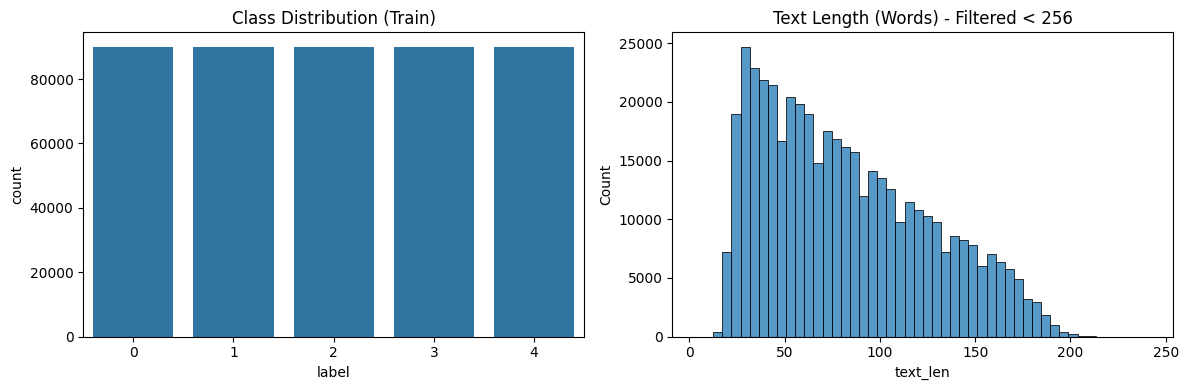

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Data Loading & Splitting ---")
# Load chunks until we have enough data (we only need the first chunk if it's 500k+)
# Based on our audit, chunk 0 has 500,000 rows. Let's load the first two chunks to ensure we can stratify nicely.
train_dfs = [pd.read_parquet(PROCESSED_DIR / chunk) for chunk in amazon_manifest['train_chunks'][:2]]
raw_train_df = pd.concat(train_dfs, ignore_index=True)

# Map labels 1-5 to 0-4 for PyTorch compatibility
raw_train_df['label'] = raw_train_df['class_index'] - 1

# Stratified sample: 100,000 per class (if available) for 500,000 total
sampled_df = raw_train_df.groupby('label', group_keys=False).apply(lambda x: x.sample(min(len(x), 100000), random_state=42))

# Split into 90% Train, 10% Validation
train_df, val_df = train_test_split(sampled_df, test_size=0.1, stratify=sampled_df['label'], random_state=42)

print(f"Train set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Train class distribution:\n{train_df['label'].value_counts().sort_index().to_dict()}")

# Text Length Analysis (concatenated title and text)
train_df['text_combined'] = train_df['review_title'] + " [SEP] " + train_df['review_text']
val_df['text_combined'] = val_df['review_title'] + " [SEP] " + val_df['review_text']

train_df['text_len'] = train_df['text_combined'].apply(lambda x: len(str(x).split()))

print("\n--- Text Length Distribution (Train) ---")
print(train_df['text_len'].describe(percentiles=[.5, .75, .90, .95, .99]))

# Plot
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(data=train_df, x='label')
plt.title("Class Distribution (Train)")

plt.subplot(1, 2, 2)
sns.histplot(train_df[train_df['text_len'] < 256]['text_len'], bins=50)
plt.title("Text Length (Words) - Filtered < 256")
plt.tight_layout()
plt.savefig(ROOT / 'reports/figures/amazon_text_length_dist.png')
print(f"\nFigure saved to: reports/figures/amazon_text_length_dist.png")

# Save processed splits for Word2Vec training
train_df[['label', 'text_combined']].to_parquet(PROCESSED_DIR / 'train_sampled.parquet', index=False)
val_df[['label', 'text_combined']].to_parquet(PROCESSED_DIR / 'val_sampled.parquet', index=False)
print("Saved train_sampled.parquet and val_sampled.parquet.")

In [5]:
!pip install gensim
import pandas as pd
from gensim.utils import simple_preprocess
from collections import Counter
import json
from pathlib import Path

PROCESSED_DIR = Path('/content/drive/MyDrive/NLP_Lab/processed_data/amazon_reviews')
train_df = pd.read_parquet(PROCESSED_DIR / 'train_sampled.parquet')

print("--- Tokenization & Vocabulary Building ---")
# Tokenize using Gensim's simple_preprocess (lowercases, removes punctuation)
def tokenize(text):
    return simple_preprocess(str(text), deacc=True)

print("Tokenizing training text...")
train_tokens = train_df['text_combined'].apply(tokenize).tolist()

print("Counting vocabulary...")
word_counts = Counter()
for tokens in train_tokens:
    word_counts.update(tokens)

print(f"Total unique words before filtering: {len(word_counts)}")

# Keep words with min_count >= 3, up to 80,000 max words
MIN_COUNT = 3
MAX_VOCAB = 80000

valid_words = [w for w, c in word_counts.most_common() if c >= MIN_COUNT]
valid_words = valid_words[:MAX_VOCAB]

print(f"Vocabulary size after min_count={MIN_COUNT} and max_vocab={MAX_VOCAB}: {len(valid_words)}")

# Create mapping (0=PAD, 1=UNK)
word2idx = {'<PAD>': 0, '<UNK>': 1}
for idx, word in enumerate(valid_words, start=2):
    word2idx[word] = idx

vocab_path = PROCESSED_DIR / 'vocab.json'
with open(vocab_path, 'w') as f:
    json.dump(word2idx, f)

print(f"Vocabulary mapping saved to {vocab_path.name}.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 122.8 MB/s  0:00:00
--- Tokenization & Vocabulary Building ---
Tokenizing training text...
Counting vocabulary...
Total unique words before filtering: 252587
Vocabulary size after min_count=3 and max_vocab=80000: 80000
Vocabulary mapping saved to vocab.json.


In [8]:
from gensim.models import Word2Vec
import time
from pathlib import Path

CKPT_DIR = Path('/content/drive/MyDrive/NLP_Lab/checkpoints/word2vec_bilstm')

print("--- Training Word2Vec (Skip-gram) ---")
start_time = time.time()

# Train Word2Vec on train_tokens
w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=200,
    window=5,
    min_count=3,
    sg=1, # Skip-gram
    negative=10,
    workers=4,
    epochs=5
)

w2v_time = time.time() - start_time
print(f"Word2Vec training completed in {w2v_time:.2f} seconds.")

# Save model
w2v_path = CKPT_DIR / 'amazon_word2vec_skipgram.model'
w2v_model.save(str(w2v_path))
print(f"Word2Vec model saved to {w2v_path}")
print("Word2Vec vectors shape:", w2v_model.wv.vectors.shape)

--- Training Word2Vec (Skip-gram) ---
Word2Vec training completed in 2055.02 seconds.
Word2Vec model saved to /content/drive/MyDrive/NLP_Lab/checkpoints/word2vec_bilstm/amazon_word2vec_skipgram.model
Word2Vec vectors shape: (88917, 200)


In [9]:
import numpy as np
import json
from gensim.models import Word2Vec
from pathlib import Path

PROCESSED_DIR = Path('/content/drive/MyDrive/NLP_Lab/processed_data/amazon_reviews')
CKPT_DIR = Path('/content/drive/MyDrive/NLP_Lab/checkpoints/word2vec_bilstm')

print("--- Building PyTorch Embedding Matrix ---")

with open(PROCESSED_DIR / 'vocab.json', 'r') as f:
    word2idx = json.load(f)

w2v_model = Word2Vec.load(str(CKPT_DIR / 'amazon_word2vec_skipgram.model'))

vocab_size = len(word2idx)
embed_dim = 200

# Initialize embedding matrix
embedding_matrix = np.zeros((vocab_size, embed_dim), dtype=np.float32)
np.random.seed(42)
embedding_matrix[1] = np.random.normal(scale=0.1, size=(embed_dim,)) # UNK initialization

words_found = 0
for word, idx in word2idx.items():
    if idx >= 2: # Skip PAD and UNK
        if word in w2v_model.wv:
            embedding_matrix[idx] = w2v_model.wv[word]
            words_found += 1
        else:
            embedding_matrix[idx] = np.random.normal(scale=0.1, size=(embed_dim,))

print(f"Initialized embedding matrix shape: {embedding_matrix.shape}")
print(f"Words successfully loaded from Word2Vec: {words_found} / {vocab_size - 2}")

print("\n--- Unit Test: PAD and UNK ---")
print("PAD vector (first 5 dims):", embedding_matrix[0][:5])
print("UNK vector (first 5 dims):", embedding_matrix[1][:5])

# Assertions to strictly enforce the specification
assert np.allclose(embedding_matrix[0], 0.0), "FAIL: PAD vector is not all zeros!"
assert not np.allclose(embedding_matrix[1], 0.0), "FAIL: UNK vector is all zeros!"
print("STATUS: PASS. PAD is strictly zeroed, UNK is non-zero.")

np.save(CKPT_DIR / 'embedding_matrix.npy', embedding_matrix)
print("Saved embedding_matrix.npy to checkpoints.")

--- Building PyTorch Embedding Matrix ---
Initialized embedding matrix shape: (80002, 200)
Words successfully loaded from Word2Vec: 80000 / 80000

--- Unit Test: PAD and UNK ---
PAD vector (first 5 dims): [0. 0. 0. 0. 0.]
UNK vector (first 5 dims): [ 0.04967142 -0.01382643  0.06476885  0.15230298 -0.02341534]
STATUS: PASS. PAD is strictly zeroed, UNK is non-zero.
Saved embedding_matrix.npy to checkpoints.


In [10]:
import torch
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import json
from pathlib import Path

PROCESSED_DIR = Path('/content/drive/MyDrive/NLP_Lab/processed_data/amazon_reviews')

with open(PROCESSED_DIR / 'vocab.json', 'r') as f:
    word2idx = json.load(f)

class AmazonDataset(Dataset):
    def __init__(self, parquet_path, max_len=256):
        self.df = pd.read_parquet(parquet_path)
        self.max_len = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        text = str(row['text_combined']).split()

        # Convert to IDs with truncation
        seq = [word2idx.get(w, word2idx['<UNK>']) for w in text[:self.max_len]]

        # Pad sequence
        if len(seq) < self.max_len:
            seq = seq + [word2idx['<PAD>']] * (self.max_len - len(seq))

        return {
            'input_ids': torch.tensor(seq, dtype=torch.long),
            'label': torch.tensor(row['label'], dtype=torch.long)
        }

print("--- Preparing DataLoaders ---")
train_dataset = AmazonDataset(PROCESSED_DIR / 'train_sampled.parquet')
val_dataset = AmazonDataset(PROCESSED_DIR / 'val_sampled.parquet')

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

--- Preparing DataLoaders ---
Train batches: 7032
Validation batches: 782


In [11]:
import torch.nn as nn
import numpy as np

class AmazonBiLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes, embedding_matrix=None):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        if embedding_matrix is not None:
            self.embedding.weight.data.copy_(torch.from_numpy(embedding_matrix))
            # We will keep embeddings trainable per standard practice, but initialized from W2V

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3
        )

        self.dropout = nn.Dropout(0.3)
        # hidden_dim * 2 because it's bidirectional
        self.classifier = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, input_ids):
        # input_ids: (batch, seq_len)
        embedded = self.embedding(input_ids) # (batch, seq_len, embed_dim)

        lstm_out, (hidden, cell) = self.lstm(embedded)

        # Concatenate the final forward and backward hidden states from the last layer
        hidden_forward = hidden[-2, :, :]
        hidden_backward = hidden[-1, :, :]
        hidden_concat = torch.cat((hidden_forward, hidden_backward), dim=1) # (batch, hidden_dim * 2)

        dropped = self.dropout(hidden_concat)
        logits = self.classifier(dropped) # (batch, num_classes)
        return logits

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

print("Model architecture defined.")

Model architecture defined.


In [12]:
import torch.optim as optim

CKPT_DIR = Path('/content/drive/MyDrive/NLP_Lab/checkpoints/word2vec_bilstm')
embedding_matrix = np.load(CKPT_DIR / 'embedding_matrix.npy')

vocab_size = embedding_matrix.shape[0]
embed_dim = 200
hidden_dim = 128
num_classes = 5

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"--- Model Instantiation on {device} ---")

# We instantiate the Word2Vec initialized model here
model = AmazonBiLSTM(vocab_size, embed_dim, hidden_dim, num_classes, embedding_matrix).to(device)
total_params, trainable_params = count_parameters(model)

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

print("\n--- Diagnostic Overfit Test ---")
# Grab one tiny batch to ensure the training loop can actually learn
test_batch = next(iter(train_loader))
inputs = test_batch['input_ids'].to(device)
targets = test_batch['label'].to(device)

optimizer = optim.AdamW(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for i in range(5):
    optimizer.zero_grad()
    outputs = model(inputs)
    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()
    print(f"Step {i+1} Loss: {loss.item():.4f}")

print("Diagnostic complete. If loss decreased, the model is capable of learning.")

--- Model Instantiation on cuda ---
Total Parameters: 16,734,869
Trainable Parameters: 16,734,869

--- Diagnostic Overfit Test ---
Step 1 Loss: 1.6067
Step 2 Loss: 1.5983
Step 3 Loss: 1.5854
Step 4 Loss: 1.5845
Step 5 Loss: 1.5703
Diagnostic complete. If loss decreased, the model is capable of learning.


In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
from pathlib import Path
from sklearn.metrics import f1_score
import json

def train_model(model, train_loader, val_loader, model_name, epochs=3, patience=2):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    # 1e-3 learning rate as per specification
    optimizer = optim.AdamW(model.parameters(), lr=1e-3)

    CKPT_DIR = Path('/content/drive/MyDrive/NLP_Lab/checkpoints/word2vec_bilstm')
    best_val_f1 = 0.0
    patience_counter = 0
    history = {'train_loss': [], 'val_loss': [], 'val_macro_f1': []}

    print(f"--- Training {model_name} on {device} ---")

    for epoch in range(epochs):
        start_time = time.time()
        model.train()
        total_loss = 0

        for batch in train_loader:
            inputs = batch['input_ids'].to(device)
            targets = batch['label'].to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()

            # Gradient clipping to ensure stability
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()

        avg_train_loss = total_loss / len(train_loader)

        # Validation Phase
        model.eval()
        val_loss = 0
        all_preds = []
        all_targets = []

        with torch.no_grad():
            for batch in val_loader:
                inputs = batch['input_ids'].to(device)
                targets = batch['label'].to(device)
                outputs = model(inputs)

                loss = criterion(outputs, targets)
                val_loss += loss.item()

                preds = torch.argmax(outputs, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(targets.cpu().numpy())

        avg_val_loss = val_loss / len(val_loader)
        val_f1 = f1_score(all_targets, all_preds, average='macro')

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['val_macro_f1'].append(val_f1)

        epoch_time = time.time() - start_time
        print(f"Epoch {epoch+1}/{epochs} | Time: {epoch_time:.0f}s")
        print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Macro-F1: {val_f1:.4f}")

        # Early Stopping & Checkpointing
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            patience_counter = 0
            ckpt_path = CKPT_DIR / f"{model_name}_best.pt"
            torch.save(model.state_dict(), ckpt_path)
            print(f"-> New best model saved to {ckpt_path.name}")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered after {epoch+1} epochs.")
                break

    # Save history
    with open(CKPT_DIR / f"{model_name}_history.json", "w") as f:
        json.dump(history, f, indent=2)

    return history

print("Training loop module defined.")

Training loop module defined.


In [14]:
print("--- Instantiating Random Baseline Model ---")
# Explicitly passing None for the embedding matrix
baseline_model = AmazonBiLSTM(
    vocab_size=vocab_size,
    embed_dim=embed_dim,
    hidden_dim=hidden_dim,
    num_classes=num_classes,
    embedding_matrix=None
)

baseline_history = train_model(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="baseline_bilstm",
    epochs=3
)

--- Instantiating Random Baseline Model ---
--- Training baseline_bilstm on cuda ---
Epoch 1/3 | Time: 357s
Train Loss: 1.2095 | Val Loss: 1.1147 | Val Macro-F1: 0.5023
-> New best model saved to baseline_bilstm_best.pt
Epoch 2/3 | Time: 355s
Train Loss: 1.0595 | Val Loss: 1.0725 | Val Macro-F1: 0.5326
-> New best model saved to baseline_bilstm_best.pt
Epoch 3/3 | Time: 354s
Train Loss: 0.9935 | Val Loss: 1.0664 | Val Macro-F1: 0.5336
-> New best model saved to baseline_bilstm_best.pt


In [15]:
print("--- Instantiating Word2Vec-Initialized Model ---")
# Instantiate fresh to clear out the diagnostic test state
w2v_bilstm_model = AmazonBiLSTM(
    vocab_size=vocab_size,
    embed_dim=embed_dim,
    hidden_dim=hidden_dim,
    num_classes=num_classes,
    embedding_matrix=embedding_matrix
)

w2v_history = train_model(
    model=w2v_bilstm_model,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="w2v_bilstm",
    epochs=3
)

--- Instantiating Word2Vec-Initialized Model ---
--- Training w2v_bilstm on cuda ---
Epoch 1/3 | Time: 361s
Train Loss: 1.1835 | Val Loss: 1.0965 | Val Macro-F1: 0.5139
-> New best model saved to w2v_bilstm_best.pt
Epoch 2/3 | Time: 356s
Train Loss: 1.0404 | Val Loss: 1.0675 | Val Macro-F1: 0.5342
-> New best model saved to w2v_bilstm_best.pt
Epoch 3/3 | Time: 355s
Train Loss: 0.9550 | Val Loss: 1.0913 | Val Macro-F1: 0.5303


In [16]:
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import json

print("--- Preparing Test Set ---")
# Load test chunks from our manifest
test_dfs = [pd.read_parquet(PROCESSED_DIR / chunk) for chunk in amazon_manifest['test_chunks']]
raw_test_df = pd.concat(test_dfs, ignore_index=True)
raw_test_df['label'] = raw_test_df['class_index'] - 1
raw_test_df['text_combined'] = raw_test_df['review_title'] + " [SEP] " + raw_test_df['review_text']

# Sample 50,000 for a realistic, quick evaluation
test_df = raw_test_df.sample(50000, random_state=42)
test_df.to_parquet(PROCESSED_DIR / 'test_sampled.parquet', index=False)

test_dataset = AmazonDataset(PROCESSED_DIR / 'test_sampled.parquet')
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

def evaluate_test(model_name, use_embedding):
    print(f"\n--- Evaluating {model_name} on Test Set ---")
    emb = embedding_matrix if use_embedding else None
    model = AmazonBiLSTM(vocab_size, embed_dim, hidden_dim, num_classes, emb).to(device)
    model.load_state_dict(torch.load(CKPT_DIR / f"{model_name}_best.pt"))
    model.eval()

    all_preds, all_targets = [], []
    with torch.no_grad():
        for batch in test_loader:
            inputs = batch['input_ids'].to(device)
            targets = batch['label'].to(device)
            outputs = model(inputs)
            all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average='macro')
    weighted_f1 = f1_score(all_targets, all_preds, average='weighted')
    mae = mean_absolute_error(all_targets, all_preds) # Useful ordinal error metric

    print(f"Test Accuracy: {acc:.4f} | Macro-F1: {macro_f1:.4f} | Weighted-F1: {weighted_f1:.4f} | MAE: {mae:.4f}")

    return all_targets, all_preds, {"accuracy": acc, "macro_f1": macro_f1, "weighted_f1": weighted_f1, "mae": mae}

_, _, base_metrics = evaluate_test("baseline_bilstm", False)
test_targets, test_preds, w2v_metrics = evaluate_test("w2v_bilstm", True)

# Save final test metrics
with open(CKPT_DIR / 'final_test_metrics.json', 'w') as f:
    json.dump({"baseline": base_metrics, "word2vec": w2v_metrics}, f, indent=2)

--- Preparing Test Set ---

--- Evaluating baseline_bilstm on Test Set ---
Test Accuracy: 0.5379 | Macro-F1: 0.5333 | Weighted-F1: 0.5332 | MAE: 0.6299

--- Evaluating w2v_bilstm on Test Set ---
Test Accuracy: 0.5357 | Macro-F1: 0.5337 | Weighted-F1: 0.5335 | MAE: 0.6225



--- Word2Vec BiLSTM Classification Report ---
              precision    recall  f1-score   support

      1 star       0.60      0.68      0.64      9933
     2 stars       0.47      0.45      0.46      9985
     3 stars       0.47      0.44      0.45     10024
     4 stars       0.50      0.49      0.49     10049
     5 stars       0.63      0.62      0.62     10009

    accuracy                           0.54     50000
   macro avg       0.53      0.54      0.53     50000
weighted avg       0.53      0.54      0.53     50000

Confusion matrix saved to amazon_confusion_matrix.png


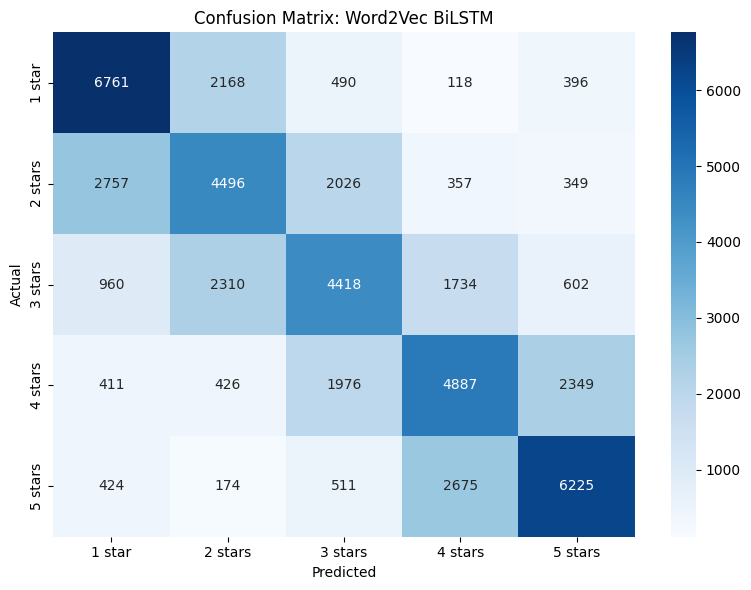

In [17]:
print("\n--- Word2Vec BiLSTM Classification Report ---")
target_names = ["1 star", "2 stars", "3 stars", "4 stars", "5 stars"]
report = classification_report(test_targets, test_preds, target_names=target_names, output_dict=True)
print(classification_report(test_targets, test_preds, target_names=target_names))

with open(CKPT_DIR / 'w2v_classification_report.json', 'w') as f:
    json.dump(report, f, indent=2)

# Confusion Matrix
cm = confusion_matrix(test_targets, test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix: Word2Vec BiLSTM')
plt.tight_layout()

cm_path = ROOT / 'reports/figures/amazon_confusion_matrix.png'
plt.savefig(cm_path)
print(f"Confusion matrix saved to {cm_path.name}")

In [18]:
print("--- Error Analysis ---")
# Find examples where the model was wrong by more than 1 star (severe misses)
test_df['predicted'] = test_preds
severe_errors = test_df[abs(test_df['label'] - test_df['predicted']) > 1].head(3)

print("Sample severe errors (Difference > 1 star):")
for _, row in severe_errors.iterrows():
    print(f"\nActual: {row['label']+1} | Predicted: {row['predicted']+1}")
    print(f"Text: {row['text_combined'][:200]}...")

print("\n--- Final Notebook 01 Gates ---")
expected_files = [
    CKPT_DIR / 'amazon_word2vec_skipgram.model',
    CKPT_DIR / 'w2v_bilstm_best.pt',
    CKPT_DIR / 'final_test_metrics.json',
    CKPT_DIR / 'w2v_classification_report.json',
    ROOT / 'reports/figures/amazon_confusion_matrix.png'
]

all_passed = True
for f in expected_files:
    status = 'PASS' if f.exists() and f.stat().st_size > 0 else 'FAIL'
    print(f"{f.name:35} | {status}")
    if status == 'FAIL': all_passed = False

if all_passed:
    print("\nSTATUS: PASS. Model A pipeline is complete and verified.")
else:
    print("\nSTATUS: FAIL. Missing artifacts.")

--- Error Analysis ---
Sample severe errors (Difference > 1 star):

Actual: 1 | Predicted: 5
Text: Fuzzy Logic [SEP] Something NOT being disproven[sic] doesn't make it true. Example: You can't prove there isn't a tooth fairy....

Actual: 5 | Predicted: 1
Text: Protect your investment. [SEP] This case is a big improvement over carrying my lantern in the original cardboard box it came in. Even though this purchase basically doubles the cost of the lantern now...

Actual: 3 | Predicted: 1
Text: D Mannose 500 milligram [SEP] I ordered this product because I read that it worked for uti. However it took so long to ship that I had to get help before this even came in the mail. It took so long to...

--- Final Notebook 01 Gates ---
amazon_word2vec_skipgram.model      | PASS
w2v_bilstm_best.pt                  | PASS
final_test_metrics.json             | PASS
w2v_classification_report.json      | PASS
amazon_confusion_matrix.png         | PASS

STATUS: PASS. Model A pipeline is complete and ver